# Среда и конфигурация

Все данные синтетические. Работа выполняется в отдельной ветке; эталон v2 не изменяется.

Найдём корень проекта. В Colab при отсутствии файлов клонируется только рабочая ветка; локально используются уже полученные исходники.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
while root != root.parent and not (root/'efc').exists():
    root = root.parent
if not (root/'efc').exists():
    import subprocess
    target = Path('/content/Forecast_Edge_Fog_Cloud')
    subprocess.run(['git','clone','--branch','night/fefc-v3','https://github.com/annfridreksen/Forecast_Edge_Fog_Cloud.git',str(target)],check=True)
    root=target
os.chdir(root)
sys.path.insert(0,str(root))
print('Рабочая папка:',root)


Рабочая папка: /home/runner/work/Forecast_Edge_Fog_Cloud/Forecast_Edge_Fog_Cloud


Что исследуем: как поток проходит Edge, отдельную FIFO одного из 50 Fog и Cloud. Интервалы из TASK.md — синтетические профили, а сетевые законы и деление Edge — явные допущения.

In [2]:
from efc.experiments import configuration_series
from efc.model import simulate,Config,COMPONENTS
from efc.views import architecture,configuration_plots,animate_task
import pandas as pd
frame=configuration_series()
display(frame)

,scenario,arrivals,completed,dropped,drop_fraction,mean_ms,p95_ms,max_ms,mean_fog_wait_ms,arrival_window_s,...,n_cloud,buffer,arrival_rate_s,seed,edge_ms,edge_fog_ms,fog_wait_ms,fog_service_ms,fog_cloud_ms,cloud_ms
0,baseline,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,8,400,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
1,edge_1250,200,200,0,0.000,120.993991,151.858899,162.663272,0.000000,1448.930319,...,8,400,0.138889,42,5.672368,5.672368,0.000000,54.368739,35.618254,19.662261
2,edge_1500,200,200,0,0.000,120.943677,151.891551,162.663272,0.000000,1207.441932,...,8,400,0.166667,42,5.647212,5.647212,0.000000,54.368739,35.618254,19.662261
3,edge_1750,200,200,0,0.000,120.962921,150.717325,162.663272,0.000000,1034.950228,...,8,400,0.194444,42,5.656834,5.656834,0.000000,54.368739,35.618254,19.662261
4,edge_2000,200,200,0,0.000,120.819027,150.062822,162.663272,0.000000,905.581449,...,8,400,0.222222,42,5.584887,5.584887,0.000000,54.368739,35.618254,19.662261
5,cloud_16,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,16,400,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
6,cloud_24,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,24,400,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
7,fog_75,200,200,0,0.000,120.785006,151.891551,162.663272,0.000000,1811.162898,...,8,400,0.111111,42,5.567876,5.567876,0.000000,54.368739,35.618254,19.662261
8,buffer_20,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,8,20,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261
9,buffer_50,200,200,0,0.000,120.767461,150.731387,162.663272,0.000000,1811.162898,...,8,50,0.111111,42,5.559104,5.559104,0.000000,54.368739,35.618254,19.662261


На схемах показаны уровни, шесть компонент и входы/выходы. Схема содержит группы устройств, но модель создаёт каждый Fog с собственной очередью.

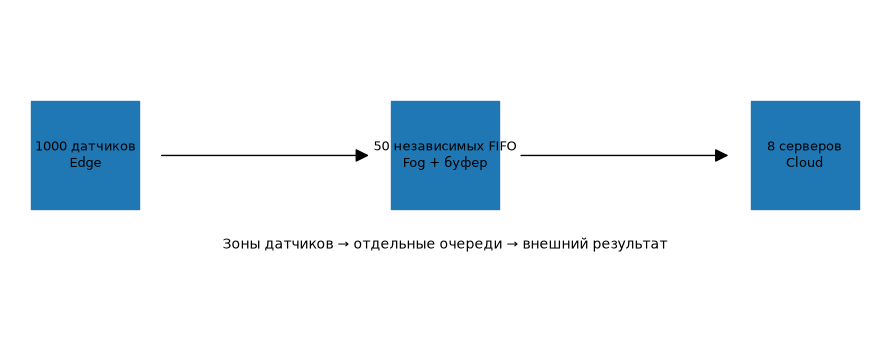

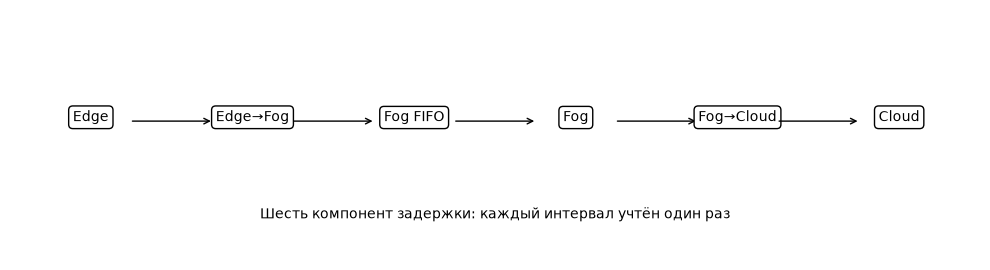

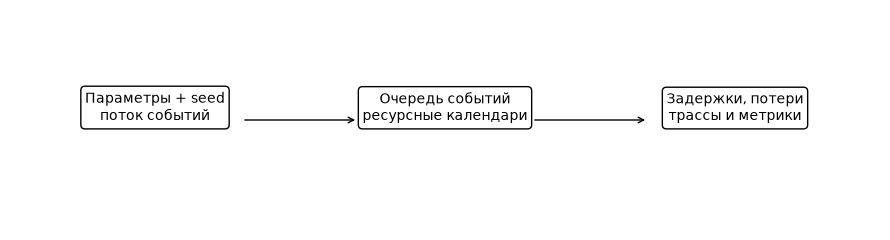

In [3]:
architecture()

Сравним конфигурации на одинаковых правилах. Стресс-серия 1200 событий/с отделена от парковочной нагрузки 400 событий/ч; по ней нельзя заявлять параметры реальной парковки.

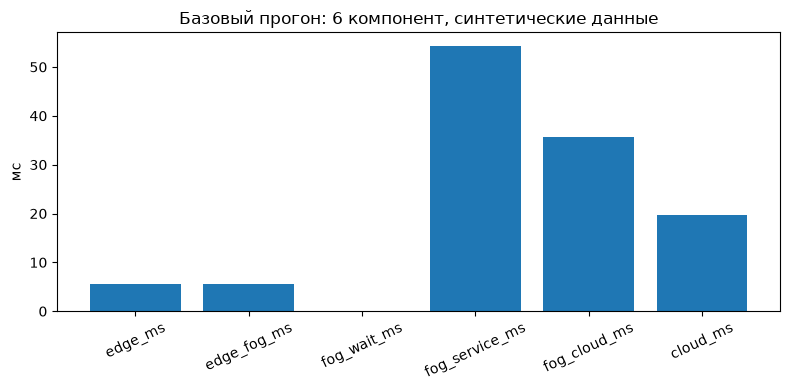

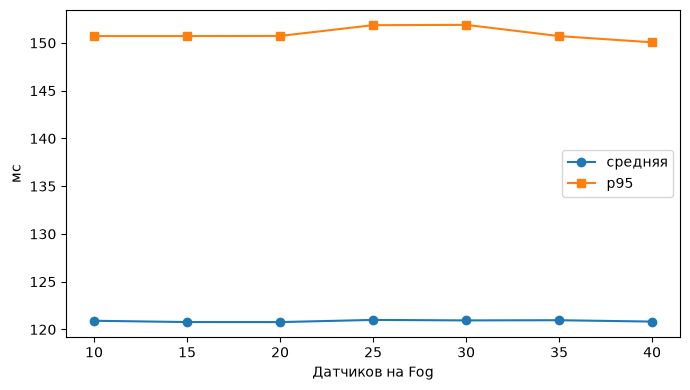

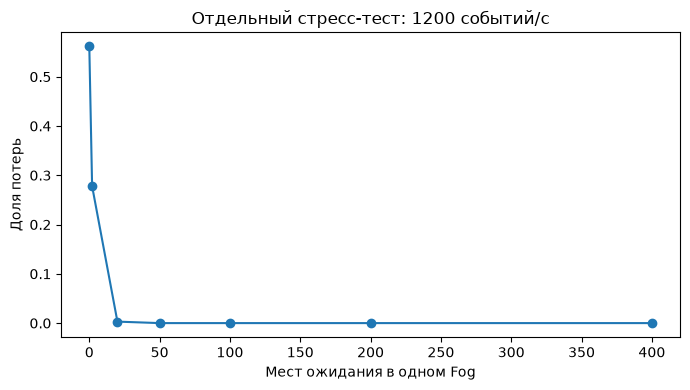

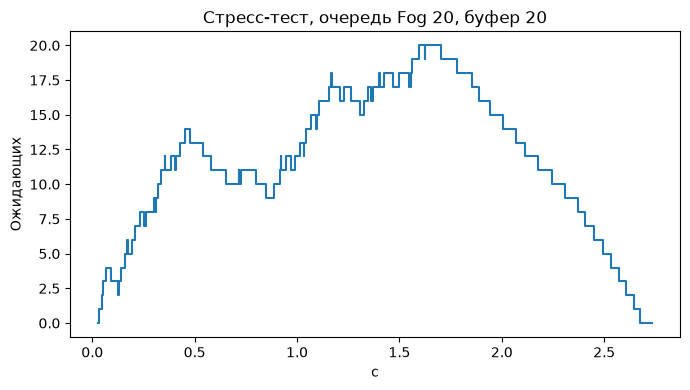

In [4]:
queue=pd.read_csv('results/stress_queue.csv')
configuration_plots(frame,queue)

Анимация одного события использует его рассчитанные интервалы, а не произвольную длительность. Базовая очередь может быть пустой — это также результат.

In [5]:
r=simulate()
html=animate_task(r['tasks'][0])
Path('results/event_animation.html').write_text(html)

300285

Ползунки изменяют параметры нового запуска. Если ipywidgets отсутствует в локальной среде, сначала установите зависимости; статические результаты выше уже воспроизводимы.

In [6]:
try:
    import ipywidgets as w
    def explore(sensors=1000,fog=50,buffer=50,mobile=0.3):
        m=simulate(Config(n_edge=sensors,n_fog=fog,buffer=buffer,mobile_fraction=mobile))['metrics']
        print({k:m[k] for k in ('mean_ms','p95_ms','mean_fog_wait_ms','dropped')})
    display(w.interactive(explore,sensors=w.IntSlider(value=1000,min=500,max=2000,step=250),fog=w.IntSlider(value=50,min=25,max=100,step=25),buffer=w.IntSlider(value=50,min=0,max=400,step=10),mobile=w.FloatSlider(value=.3,min=0,max=1,step=.1)))
except ImportError:
    print('ipywidgets не установлен: интерактивные ползунки не проверены в этой среде.')

interactive(children=(IntSlider(value=1000, description='sensors', max=2000, min=500, step=250), IntSlider(val…

Проверка: баланс событий и сумма шести компонент. Таблица чисел предназначена для прямого переноса в статью с указанием источника.

In [7]:
assert (frame.completed+frame.dropped==frame.arrivals).all()
for row in r['tasks']:
    if row['status']=='completed':
        assert abs(sum(row[k] for k in COMPONENTS)-row['latency_ms'])<1e-6
b=frame.query("scenario=='baseline'").iloc[0]
display(pd.DataFrame({'число в статье':[b.mean_ms,b.p95_ms,b.mean_fog_wait_ms],'число модели':[r['metrics']['mean_ms'],r['metrics']['p95_ms'],r['metrics']['mean_fog_wait_ms']]},index=['средняя,мс','p95,мс','Fog-ожидание,мс']))
assert abs(b.mean_ms-r['metrics']['mean_ms'])<1e-9
print('OK')

,число в статье,число модели
"средняя,мс",120.767461,120.767461
"p95,мс",150.731387,150.731387
"Fog-ожидание,мс",0.000000,0.000000


OK
